In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

CLEAN_PATH = Path("../data/processed/netflix_clean.csv")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(CLEAN_PATH, parse_dates=["date_added"])
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
df.head()

Rows: 8790, Columns: 15


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,year_added,month_added,duration_value,duration_unit,primary_country
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021,9,90,min,United States
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",2021,9,1,Season,France
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",2021,9,1,Season,United States
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",2021,9,91,min,Brazil
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",2021,9,125,min,United States


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   show_id          8790 non-null   str           
 1   type             8790 non-null   str           
 2   title            8790 non-null   str           
 3   director         8790 non-null   str           
 4   country          8790 non-null   str           
 5   date_added       8790 non-null   datetime64[us]
 6   release_year     8790 non-null   int64         
 7   rating           8790 non-null   str           
 8   duration         8790 non-null   str           
 9   listed_in        8790 non-null   str           
 10  year_added       8790 non-null   int64         
 11  month_added      8790 non-null   int64         
 12  duration_value   8790 non-null   int64         
 13  duration_unit    8790 non-null   str           
 14  primary_country  8790 non-null   str           
dty

In [3]:
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
show_id,8790,8790,s1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8790,2,Movie,6126,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8790,8786,9-Feb,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,8790,4528,Unknown,2588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,8790,86,United States,3240,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8790,NaN,NaN,NaN,2019-05-17 21:44:01.638225,2008-01-01 00:00:00,2018-04-06 00:00:00,2019-07-03 00:00:00,2020-08-19 18:00:00,2021-09-25 00:00:00,NaN
release_year,8790.0,NaN,NaN,NaN,2014.183163,1925.0,2013.0,2017.0,2019.0,2021.0,8.825466
rating,8790,14,TV-MA,3205,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8790,220,1 Season,1791,NaN,NaN,NaN,NaN,NaN,NaN,NaN
listed_in,8790,513,"Dramas, International Movies",362,NaN,NaN,NaN,NaN,NaN,NaN,NaN


type
Movie      6126
TV Show    2664
Name: count, dtype: int64

type
Movie      69.7
TV Show    30.3
Name: count, dtype: float64


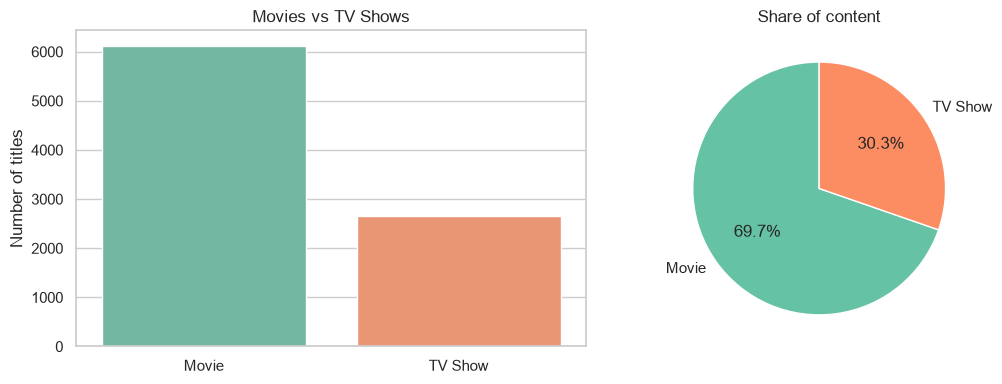

In [4]:
type_counts = df["type"].value_counts()
print(type_counts, end="\n\n")
print((type_counts / len(df) * 100).round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.countplot(data=df, x="type", hue="type", palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Movies vs TV Shows")
axes[0].set_xlabel("")
axes[0].set_ylabel("Number of titles")

axes[1].pie(type_counts, labels=type_counts.index, autopct="%1.1f%%",
            colors=sns.color_palette("Set2"), startangle=90)
axes[1].set_title("Share of content")

plt.tight_layout()
fig.savefig(FIG_DIR / "eda_type_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

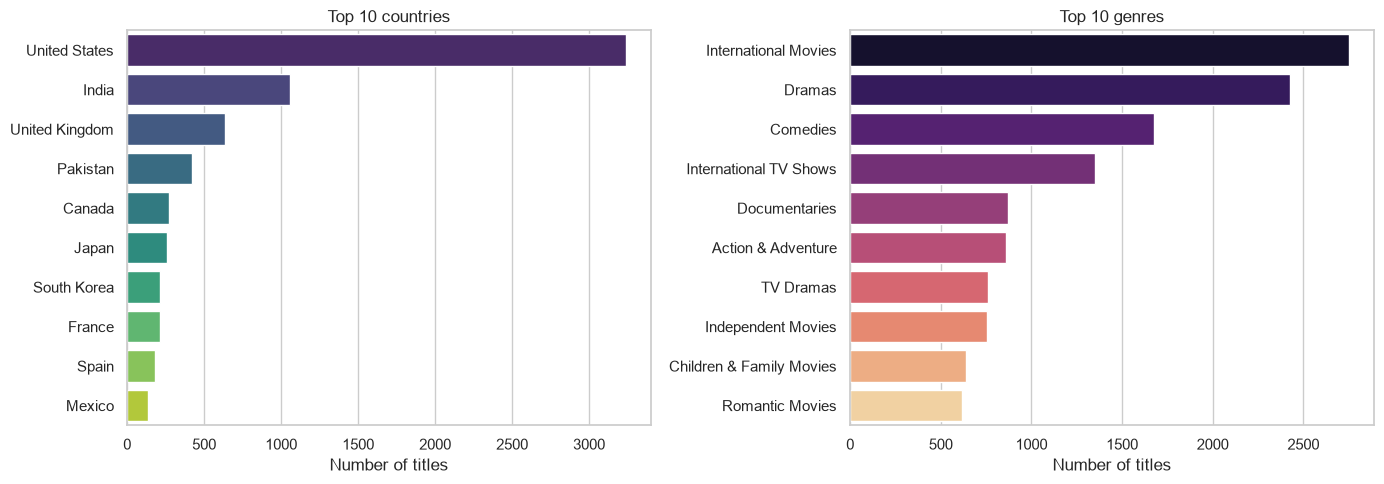

In [5]:
known = df[df["primary_country"] != "Unknown"]
top_countries = known["primary_country"].value_counts().head(10)

genres = (
    df.assign(genre=df["listed_in"].str.split(","))
    .explode("genre")
    .assign(genre=lambda d: d["genre"].str.strip())
)
top_genres = genres["genre"].value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x=top_countries.values, y=top_countries.index, hue=top_countries.index,
            palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Top 10 countries")
axes[0].set_xlabel("Number of titles")
axes[0].set_ylabel("")

sns.barplot(x=top_genres.values, y=top_genres.index, hue=top_genres.index,
            palette="magma", legend=False, ax=axes[1])
axes[1].set_title("Top 10 genres")
axes[1].set_xlabel("Number of titles")
axes[1].set_ylabel("")

plt.tight_layout()
fig.savefig(FIG_DIR / "eda_top_countries_genres.png", dpi=150, bbox_inches="tight")
plt.show()

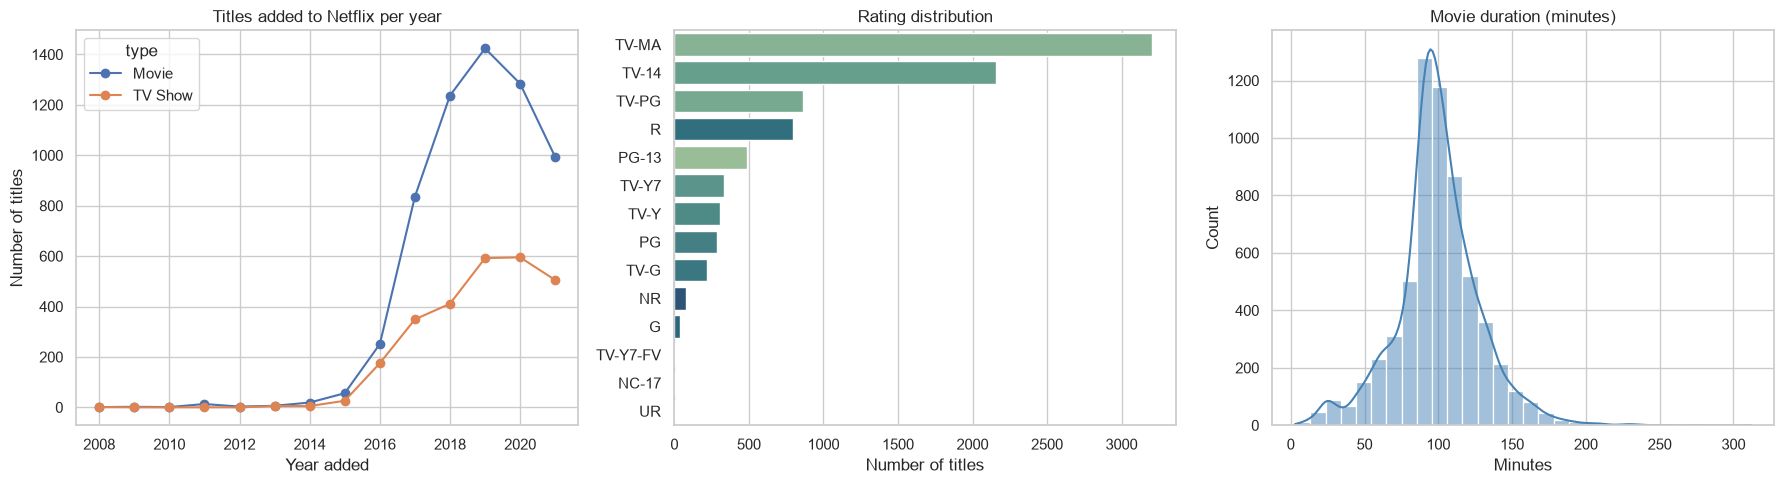

Median movie length: 98.0 min
Most common TV show length: 1 season(s)


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Content added per year, split by type
added = df.groupby(["year_added", "type"], observed=True).size().unstack(fill_value=0)
added.plot(kind="line", marker="o", ax=axes[0])
axes[0].set_title("Titles added to Netflix per year")
axes[0].set_xlabel("Year added")
axes[0].set_ylabel("Number of titles")

# 2. Rating distribution
rating_order = df["rating"].value_counts().index
sns.countplot(data=df, y="rating", order=rating_order, hue="rating",
              palette="crest", legend=False, ax=axes[1])
axes[1].set_title("Rating distribution")
axes[1].set_xlabel("Number of titles")
axes[1].set_ylabel("")

# 3. Movie duration
movies = df[df["duration_unit"] == "min"]
sns.histplot(movies["duration_value"], bins=30, kde=True, color="steelblue", ax=axes[2])
axes[2].set_title("Movie duration (minutes)")
axes[2].set_xlabel("Minutes")

plt.tight_layout()
fig.savefig(FIG_DIR / "eda_trends_ratings_duration.png", dpi=150, bbox_inches="tight")
plt.show()

print("Median movie length:", movies["duration_value"].median(), "min")
print("Most common TV show length:",
      df[df["duration_unit"] == "Season"]["duration_value"].mode()[0], "season(s)")

In [9]:
print("Top 3 countries:\n", top_countries.head(3), end="\n\n")
print("Top 3 genres:\n", top_genres.head(3), end="\n\n")
print("Peak year added:", df["year_added"].value_counts().idxmax(),
      "with", df["year_added"].value_counts().max(), "titles")
print("Most common rating:", df["rating"].mode()[0])
print("Median movie length:", movies["duration_value"].median(), "min")
print("Most common TV show seasons:", df[df["type"] == "TV Show"]["duration_value"].mode()[0])

Top 3 countries:
 primary_country
United States     3240
India             1057
United Kingdom     638
Name: count, dtype: int64

Top 3 genres:
 genre
International Movies    2752
Dramas                  2426
Comedies                1674
Name: count, dtype: int64

Peak year added: 2019 with 2016 titles
Most common rating: TV-MA
Median movie length: 98.0 min
Most common TV show seasons: 1


## Key Findings

1. **Movies dominate the catalogue:** 6,126 movies (69.7%) vs 2,664 TV shows (30.3%).
2. **The US leads content production** with 3,240 titles, followed by India (1,057) and the United Kingdom (638).
3. **Top genres** are International Movies (2,752), Dramas (2,426) and Comedies (1,674).
4. **Growth peaked in 2019:** 2,016 titles were added that year. Additions grew sharply from 2016. The 2021 figure is lower because the data ends in September 2021.
5. **Mature content is most common:** TV-MA is the most frequent rating, followed by TV-14.
6. **Typical movie length is 98 minutes**, and most TV shows have just 1 season.
7. **Data quality note:** 2,588 titles have an unknown director and 287 an unknown country, so country and director analysis covers only part of the data.